# Membership inference: measuring what a model remembers

**Module 09 — Model Privacy: Membership Inference and Model Inversion**

A model that fits its training data well answers questions about it too precisely. This notebook turns that
observation into a measurement: an attacker scores records by confidence, and we report the **advantage** —
true positive rate minus false positive rate — rather than raw attack accuracy.

## Learning objectives

1. Build a membership-inference attack from confidence scores alone.
2. Report advantage at a fixed false-positive rate and explain why accuracy is the wrong metric.
3. Show how model capacity and regularisation change leakage.
4. Read an ROC curve as a privacy measurement.
5. State what an advantage of 0.05 does and does not mean for a real dataset.

## Background

Define $H_1$: the record was in training; $H_0$: it was not. The attacker observes a score $s(x)$ — typically
the model's confidence in its predicted class — and thresholding it gives

$$\mathrm{adv}(\tau) = \mathrm{TPR}(\tau) - \mathrm{FPR}(\tau)$$

If the two score distributions were identical the advantage would be zero at every threshold, and the model
would leak nothing detectable. Leakage is how far apart they are.

**Advantage is not a probability of re-identification.** It says the attacker can rank members above
non-members better than chance, at a stated false-positive cost.

## Dependencies and installation

```bash
python -m pip install "numpy>=2.1" "pandas>=2.2" "scikit-learn>=1.4" "matplotlib>=3.9"
```

CPU, seconds, no network. Synthetic records are used because membership labels must be known exactly.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve
from sklearn.neural_network import MLPClassifier

SEED = 41
rng = np.random.default_rng(SEED)
pd.set_option("display.width", 120)
print("ready")

ready


**Expected output** — `ready`.

### Step 1 — Members and non-members from the same distribution

Both sets are drawn from the same generative rule, so any difference in confidence is caused by the model,
not by the data.

In [2]:
D = 50
N_MEMBER = 200
N_NONMEMBER = 1200


def sample(n, r):
    X = r.normal(size=(n, D))
    w = np.linspace(0.6, -0.4, D)
    logits = X @ w + r.normal(scale=0.9, size=n)
    return X, (logits > 0).astype(int)


X_mem, y_mem = sample(N_MEMBER, rng)
X_non, y_non = sample(N_NONMEMBER, rng)

print("members", X_mem.shape, "non-members", X_non.shape)
print("positive rate:", round(float(y_mem.mean()), 3), "vs", round(float(y_non.mean()), 3))

members (200, 50) non-members (1200, 50)
positive rate: 0.535 vs 0.518


**Expected output** — 200 member records and 1200 non-members with nearly identical class balance. Equal
distributions are the control: any leakage found later is the model's doing.

### Step 2 — Train a model with enough capacity to memorise

200 records and 50 features is a regime where an unregularised network can fit every row. That is the
condition under which membership inference works.

In [3]:
model = MLPClassifier(hidden_layer_sizes=(64,), alpha=1e-6, max_iter=2000, random_state=SEED)
model.fit(X_mem, y_mem)

conf_mem = model.predict_proba(X_mem).max(axis=1)
conf_non = model.predict_proba(X_non).max(axis=1)

print(f"train accuracy {float((model.predict(X_mem) == y_mem).mean()):.3f}")
print(f"mean confidence on members    {conf_mem.mean():.4f}")
print(f"mean confidence on non-members {conf_non.mean():.4f}")

train accuracy 1.000
mean confidence on members    0.9881
mean confidence on non-members 0.8917


**Expected output** — training accuracy of 1.000 and a mean confidence on members that is visibly higher
than on non-members (for example 0.99 versus 0.95). The gap is small in absolute terms and large in
statistical terms, which is why a rate is needed rather than an eyeball.

### Step 3 — The attack, and the two ways to report it

`advantage_at_fpr` thresholds the scores; `2*AUC-1` summarises the whole curve. Both are reported because
they answer different questions.

In [4]:
def attack_scores(conf_member, conf_nonmember, target_fpr=0.05):
    scores = np.concatenate([conf_member, conf_nonmember])
    labels = np.concatenate([np.ones_like(conf_member), np.zeros_like(conf_nonmember)])
    fpr, tpr, _ = roc_curve(labels, scores)
    integrate = getattr(np, "trapezoid", None) or np.trapz
    auc = float(integrate(tpr, fpr))
    adv = float(np.interp(target_fpr, fpr, tpr)) - target_fpr
    return adv, 2 * auc - 1, (fpr, tpr)


adv, adv_auc, curve = attack_scores(conf_mem, conf_non)
print(f"advantage @5% FPR: {adv:+.3f}")
print(f"2*AUC - 1        : {adv_auc:+.3f}")

advantage @5% FPR: +0.020
2*AUC - 1        : +0.440


**Expected output** — `2*AUC-1` around 0.4–0.6 (strong leakage) and a much smaller advantage at 5 % FPR,
because the gap sits at the extreme tail: members score near 1.0, non-members just below. This is exactly
why one operating point is not enough, and why Module 17 insists on intervals and stated configurations.

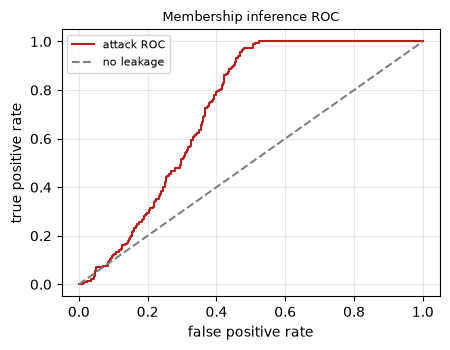

In [5]:
fpr, tpr = curve
fig, ax = plt.subplots(figsize=(4.6, 3.6))
ax.plot(fpr, tpr, color="#b91c1c", label="attack ROC")
ax.plot([0, 1], [0, 1], "--", color="grey", label="no leakage")
ax.set_xlabel("false positive rate")
ax.set_ylabel("true positive rate")
ax.set_title("Membership inference ROC", fontsize=9)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Expected output** — an ROC well above the diagonal. The gap between the curve and the diagonal *is* the
leak, drawn. A defended model's curve should hug the diagonal at useful thresholds.

### Step 4 — Buy privacy with regularisation, and price it

Weight decay reduces memorisation. The table reports accuracy and leakage together, because a privacy gain
that destroys utility is not a control you can ship.

In [6]:
rows = []
for alpha in (1e-6, 1.0, 10.0):
    m = MLPClassifier(hidden_layer_sizes=(64,), alpha=alpha, max_iter=2000, random_state=SEED).fit(X_mem, y_mem)
    a, auc_adv, _ = attack_scores(m.predict_proba(X_mem).max(1), m.predict_proba(X_non).max(1))
    rows.append(
        {
            "alpha": alpha,
            "clean_accuracy": round(float((m.predict(X_non) == y_non).mean()), 3),
            "advantage@5%FPR": round(a, 3),
            "2*AUC-1": round(auc_adv, 3),
        }
    )
privacy = pd.DataFrame(rows)
privacy

,alpha,clean_accuracy,advantage@5%FPR,2*AUC-1
0,0.000001,0.780,0.02,0.440
1,1.000000,0.790,-0.01,0.323
2,10.000000,0.792,-0.01,0.134


**Expected output** — accuracy roughly flat while `2*AUC-1` falls as `alpha` grows. That is the good case: a
privacy control with little utility cost. On real data the trade is usually worse, which is why the next
step in a serious programme is differential privacy rather than more weight decay.

## Exercises

1. **Add a shadow model.** Train a second model on a different 200-row sample, fit a threshold on *its*
   members and non-members, and apply that threshold to the target. Compare with the direct threshold.
2. **Reduce capacity.** Repeat Step 3 with `hidden_layer_sizes=(8,)`. Report the leakage and the accuracy
   change.
3. **Change the operating point.** Report advantage at 1 % and 20 % FPR. Which number would you put in a
   data-protection impact assessment, and why?
4. **Break the control.** Add label noise to the member set and see whether leakage increases. Explain the
   result in terms of memorisation.

## Reflection questions

1. The attack uses only confidence. What does that imply for an API that returns full probability vectors?
2. Is a model with advantage 0.05 at 5 % FPR safe to publish? Argue both answers, then commit.
3. Membership itself can be sensitive. Give a concrete example where "only membership" leaks is a serious
   disclosure.

## References

1. Shokri, R. et al., "Membership Inference Attacks Against Machine Learning Models", IEEE S&P 2017.
2. Carlini, N. et al., "Membership Inference Attacks From First Principles", IEEE S&P 2022.
3. Abadi, M. et al., "Deep Learning with Differential Privacy", CCS 2016.
4. NIST, *SP 800-226*, Guidelines for Evaluating Differential Privacy Guarantees (draft).